In [10]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

In [3]:
import xgboost as xgb

In [13]:
waves = pd.read_csv('waves_2023.txt', sep=r'\s+')

In [14]:
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [15]:
# Only need: WVHT, DPD, APD, MWD, WTM
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE','YY','MM','DD','hh','mm'], axis=1) 
# drop the 999 values
waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [16]:
waves.describe()

,WVHT,DPD,APD,MWD,WTMP
count,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000
mean,1.032525,12.116640,6.765029,234.157965,17.195294
std,0.526637,3.664928,1.852623,46.260000,2.564729
min,0.330000,2.860000,3.420000,10.000000,11.800000
25%,0.730000,9.090000,5.500000,179.000000,14.600000
50%,0.880000,12.500000,6.360000,263.000000,17.500000
75%,1.140000,14.290000,7.550000,271.000000,19.400000
max,5.130000,25.000000,15.790000,306.000000,23.900000


In [17]:
from sklearn import linear_model
from xgboost import XGBClassifier

In [18]:
df_X = waves.drop(['WVHT'],axis=1).to_numpy() 
df_y = waves['WVHT'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10)

In [19]:
# make boosted forest

In [20]:
boost = xgb.XGBRegressor(n_estimators=25)
boost.fit(X_train, y_train)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [21]:
# training error
Ypredtrain = boost.predict(X_train)
mean_squared_error(Ypredtrain, y_train)

0.07548653482446588

In [22]:
# validation error
Ypred = boost.predict(X_val)
mean_squared_error(Ypred,y_val)

0.0914823701337754

In [23]:
# testing error
Ypredtest = boost.predict(X_test)
mean_squared_error(Ypredtest,y_test)

0.08954314788320329

In [24]:
# Compare to linear model

In [25]:
linear_reg = linear_model.LinearRegression()
linear_reg.fit(df_X,df_y)

regtrain= linear_reg.predict(X_train)
regval= linear_reg.predict(X_val)
regtest = linear_reg.predict(X_test)

print('LINEAR:','training mse:', mean_squared_error(regtrain,y_train),'validation mse:', mean_squared_error(regval,y_val),'testing mse:', mean_squared_error(regtest,y_test))
print('BOOSTED:','training mse:',mean_squared_error(Ypredtrain, y_train),'Validation mse:',mean_squared_error(Ypred,y_val),'testing mse:',mean_squared_error(Ypredtest,y_test))

LINEAR: training mse: 0.1966252119627367 validation mse: 0.20541291662656624 testing mse: 0.17902905021260582
BOOSTED: training mse: 0.07548653482446588 Validation mse: 0.0914823701337754 testing mse: 0.08954314788320329


In [26]:
# The boosted regression model is more accurate across training, validation, and testing sets

In [27]:
# For the boosted regression tree, XGBoost uses a mean squared error loss funtion by default
# For the linear model, the cost function is an ordinary least squares cost function
# I didn't optimize any hyperparameters, as the only one I used was the number of iterations (25) which was determined by the question

In [28]:
# Train a boosted regression tree on this prediction task with 2, 10, 25, 50, 100, 250, 500, & 1,000 boosting iterations.
# Plot the training and validation error as a function of number of iterations

In [29]:
ntrees = [2, 10, 25, 50, 100, 250, 500, 1000]
valscores = [] 
trainscores = []

for n in ntrees:
    boostn = xgb.XGBRegressor(n_estimators=n)
    boostn.fit(X_train, y_train)                                                          
    valscores.append(boostn.score(X_val, y_val))
    trainscores.append(boostn.score(X_train, y_train))     

In [30]:
print(valscores, trainscores)

[0.40910871477777255, 0.6324221110340902, 0.6695770432920958, 0.6944557867561911, 0.7137548222883029, 0.7098058474078976, 0.6974598012903828, 0.6833712795708942] [0.4442330816844714, 0.6737344444258632, 0.7309910672813342, 0.7870635847153962, 0.8439323204425735, 0.916938173409828, 0.9576002452105413, 0.985456294679088]


In [31]:
a = {
    "Training scores": trainscores,
    "Validation scores": valscores,
    "Number of Trees": ['2', '10', '25', '50', '100', '250', '500', '1000'] 
}

df = pd.DataFrame(a)

Text(0.5, 1.0, 'Scores of models with different number of trees')

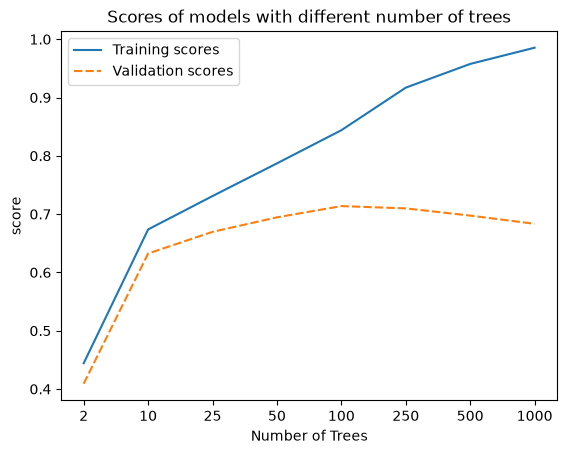

In [32]:
xlabels = (2,10,25,50,100,250,500,1000)
xticks = (0,1,2,3,4,5,6,7)
p = sns.lineplot(data=df).set_xticks(xticks, labels=xlabels)
plt.xlabel('Number of Trees')
plt.ylabel('score')
plt.title("Scores of models with different number of trees")

In [33]:
# There is evidence of overfitting, the training and validation scores diverge, with validation scores dropping after ~100 trees

In [34]:
# Retrain the boosted regression tree using early stopping with a tolerance of 10. How many boosting iterations were optimal?

In [35]:
earlystop = xgb.XGBRegressor(
    n_estimators=1000,
    learning_rate=0.1,
    max_depth=6,
    early_stopping_rounds=10, #tolerance of 10
)

earlystop.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=10,
)

print(f"Best iteration: {earlystop.best_iteration}")

[0]	validation_0-rmse:0.50004	validation_1-rmse:0.49938
[10]	validation_0-rmse:0.35580	validation_1-rmse:0.36519
[20]	validation_0-rmse:0.31873	validation_1-rmse:0.33367
[30]	validation_0-rmse:0.30170	validation_1-rmse:0.31981
[40]	validation_0-rmse:0.29255	validation_1-rmse:0.31478
[50]	validation_0-rmse:0.28663	validation_1-rmse:0.31023
[60]	validation_0-rmse:0.27976	validation_1-rmse:0.30494
[70]	validation_0-rmse:0.27569	validation_1-rmse:0.30257
[80]	validation_0-rmse:0.26919	validation_1-rmse:0.29972
[90]	validation_0-rmse:0.26363	validation_1-rmse:0.29663
[100]	validation_0-rmse:0.26091	validation_1-rmse:0.29590
[110]	validation_0-rmse:0.25789	validation_1-rmse:0.29471
[120]	validation_0-rmse:0.25578	validation_1-rmse:0.29384
[130]	validation_0-rmse:0.25370	validation_1-rmse:0.29310
[140]	validation_0-rmse:0.25053	validation_1-rmse:0.29179
[150]	validation_0-rmse:0.24792	validation_1-rmse:0.29060
[160]	validation_0-rmse:0.24361	validation_1-rmse:0.29002
[170]	validation_0-rmse:0

In [36]:
# With a tolerance of 10, the optimal number of iterations is 243